# 3. importer des librairies

In [17]:
import pandas as pd #pour manipuler les donnes sous forme de tableau (nettoyer les donner manquante , excel surpuissant)

In [65]:
import seaborn as sns# rend les graphiques moderne et jolie, cree des graphoques complexes

In [20]:
import re #recherche et manipulation de texte

In [19]:
from dateutil.relativedelta import relativedelta #pour nous permetre de calculer l'age, clacule la differenece exacte entre deux date


In [21]:
import numpy as np # permet de manipuler les tableaux de nombre de maniere rapide  (matrice)

# 4. Creer les dataframes

In [15]:
df = pd.read_excel('donnee_milliardaires.xlsx', sheet_name='Sauvegarde')#permet de lire les donnes et de l'attribuer dans une data frame

In [16]:
df.head()#pour voir ce qui es dans la dataframe

,rang,categorie,prenomNom,pays,ville,source,domaine,luiMeme,genre,nom,...,revenuFinal,anneeNaissance,moisNaissance,jourNaissance,cpi_pays,pib_pays,esperance_ de_vie_pays,tax_revenue_pays,total_taux_imposition_pays,population_pays
0,1,Mode & Commerce,Bernard Arnault & family,France,Paris,LVMH,Fashion & Retail,False,H,Arnault,...,211000,1949,3,5,110.05,"$2,715,518,274,227",82.5,24.2,60.7,67059887
1,2,Automobile,Elon Musk,États-Unis,Austin,"Tesla, SpaceX",Automotive,True,H,Musk,...,180000,1971,6,28,117.24,"$21,427,700,000,000",78.5,9.6,36.6,328239523
2,3,Technologie,Jeff Bezos,États-Unis,Medina,Amazon,Technology,True,H,Bezos,...,114000,1964,1,12,117.24,"$21,427,700,000,000",78.5,9.6,36.6,328239523
3,4,Technologie,Larry Ellison,États-Unis,Lanai,Oracle,Technology,True,H,Ellison,...,107000,1944,8,17,117.24,"$21,427,700,000,000",78.5,9.6,36.6,328239523
4,5,Finance & Investissements,Warren Buffett,États-Unis,Omaha,Berkshire Hathaway,Finance & Investments,True,H,Buffett,...,106000,1930,8,30,117.24,"$21,427,700,000,000",78.5,9.6,36.6,328239523


In [22]:
df.shape # pour connaitre le nbre de ligne et de colone de notre data_frame

(481, 21)

In [24]:
df.dtypes #pour visualliser le type de chaque donnes

rang                            int64
categorie                         str
prenomNom                         str
pays                              str
ville                             str
source                            str
domaine                           str
luiMeme                          bool
genre                             str
nom                               str
prenom                            str
revenuFinal                     int64
anneeNaissance                  int64
moisNaissance                   int64
jourNaissance                   int64
cpi_pays                      float64
pib_pays                          str
esperance_ de_vie_pays        float64
tax_revenue_pays              float64
total_taux_imposition_pays    float64
population_pays                 int64
dtype: object

# 5. nettoyage des donnes

# 5.1 donnes manquantes

In [25]:
df[df.isna()].count() #pour le denander de commpter les valeurs nulles par colones 

rang                          0
categorie                     0
prenomNom                     0
pays                          0
ville                         0
source                        0
domaine                       0
luiMeme                       0
genre                         0
nom                           0
prenom                        0
revenuFinal                   0
anneeNaissance                0
moisNaissance                 0
jourNaissance                 0
cpi_pays                      0
pib_pays                      0
esperance_ de_vie_pays        0
tax_revenue_pays              0
total_taux_imposition_pays    0
population_pays               0
dtype: int64

# 5.2 Suppression des doublons(pour eviter les erreurs)

In [26]:
df[df.duplicated()].count() # pour compter les doublons

rang                          6
categorie                     6
prenomNom                     6
pays                          6
ville                         6
source                        6
domaine                       6
luiMeme                       6
genre                         6
nom                           6
prenom                        6
revenuFinal                   6
anneeNaissance                6
moisNaissance                 6
jourNaissance                 6
cpi_pays                      6
pib_pays                      6
esperance_ de_vie_pays        6
tax_revenue_pays              6
total_taux_imposition_pays    6
population_pays               6
dtype: int64

In [27]:
df = df.drop_duplicates()# pour suprimmer les doublbons

In [28]:
df.shape # histoire de verifier si les doublións ont ete vraiment effacer 

(475, 21)

# 5.3 Remplacer des valeur

In [29]:
df['genre'].value_counts()# nous permet de voir quels types de valeur on a a 'genre' et combien

genre
H    407
F     68
Name: count, dtype: int64

In [30]:
df['genre'] = df['genre'].replace(to_replace=[r'^F$',r'^H$'],value=['femme','homme'],regex=True ,inplace = False)# tout ca pour remplacer les types de valeurs

In [31]:
df['genre'].value_counts()#histoire de tester si ca a marcher

genre
homme    407
femme     68
Name: count, dtype: int64

# 5.4. Ajuster le type de la colonne pib_pays

In [32]:
df.dtypes

rang                            int64
categorie                         str
prenomNom                         str
pays                              str
ville                             str
source                            str
domaine                           str
luiMeme                          bool
genre                             str
nom                               str
prenom                            str
revenuFinal                     int64
anneeNaissance                  int64
moisNaissance                   int64
jourNaissance                   int64
cpi_pays                      float64
pib_pays                          str
esperance_ de_vie_pays        float64
tax_revenue_pays              float64
total_taux_imposition_pays    float64
population_pays                 int64
dtype: object

In [34]:
df['pib_pays'].head(2)#pour visualiser juste 2 colones de donnes du pib_pays

0     $2,715,518,274,227 
1    $21,427,700,000,000 
Name: pib_pays, dtype: str

In [35]:
df['pib_pays'].astype('float64')# si on essaye de le convertir en flottant on a un erreur du au signe du $ qui n'est pas considerer conme un nombre

ValueError: could not convert string to float: '$2,715,518,274,227 '

In [37]:
list_pib = df['pib_pays'].to_list()# methode de pandas pour transformer en liste un ensembles de donnes 
list_pib_nouv = []
for el in list_pib:
    el = re.sub(r'[^\d]+','',el)# cet regex demande a python de regarder dans la chaine de caractere 'el' tout ce qui n'est pas numerique ([^\d = ce qui es non digital] ) et de le remplacer par le vide ''
    list_pib_nouv.append(el)
print(list_pib[0],list_pib_nouv[0])
      

$2,715,518,274,227  2715518274227


In [39]:
df['pib_pays'] = pd.Series(list_pib_nouv)# pour transformer list_pib_nouv en une serie/colone et l'assigner 

In [40]:
df['pib_pays'] = df['pib_pays'].astype('float64')

In [41]:
df['pib_pays'].dtypes

dtype('float64')

In [42]:
df['pib_pays'].head()

0    2.715518e+12
1    2.142770e+13
2    2.142770e+13
3    2.142770e+13
4    2.142770e+13
Name: pib_pays, dtype: float64

# 5.5 Ajouter la colonne age

In [43]:
df.columns

Index(['rang', 'categorie', 'prenomNom', 'pays', 'ville', 'source', 'domaine',
       'luiMeme', 'genre', 'nom', 'prenom', 'revenuFinal', 'anneeNaissance',
       'moisNaissance', 'jourNaissance', 'cpi_pays', 'pib_pays',
       'esperance_ de_vie_pays', 'tax_revenue_pays',
       'total_taux_imposition_pays', 'population_pays'],
      dtype='str')

In [46]:
df['dateNaissance'] = df['jourNaissance'].astype('str') + '-' + df['moisNaissance'].astype('str') + '-'+df['anneeNaissance'].astype('str') # on cree une nouvelle colone et on convertis en chaine de caracter et on fait une concatenation

In [45]:
df['dateNaissance'].head()

0     5-3-1949
1    28-6-1971
2    12-1-1964
3    17-8-1944
4    30-8-1930
Name: dateNaissance, dtype: str

In [51]:
df['dateNaissance'] = pd.to_datetime(df['dateNaissance'] , format = '%d-%m-%Y')#pour convertir au format date

In [50]:
df['dateNaissance'].dtypes

dtype('<M8[us]')

In [52]:
df['today'] = pd.to_datetime('now')

In [53]:
df['age'] = df.apply(lambda x: relativedelta(x.today, x.dateNaissance).years, axis = 1)# la methode relativedelta permet de claculer la diff entre 2  dates

In [54]:
df['age'].head()

0    77
1    54
2    62
3    81
4    95
Name: age, dtype: int64

# 6. Analyse des donnes

# 6.1 Lister le top 5 des milliardaires

In [55]:
df.columns 

Index(['rang', 'categorie', 'prenomNom', 'pays', 'ville', 'source', 'domaine',
       'luiMeme', 'genre', 'nom', 'prenom', 'revenuFinal', 'anneeNaissance',
       'moisNaissance', 'jourNaissance', 'cpi_pays', 'pib_pays',
       'esperance_ de_vie_pays', 'tax_revenue_pays',
       'total_taux_imposition_pays', 'population_pays', 'dateNaissance',
       'today', 'age'],
      dtype='str')

In [56]:
df = df.sort_values(by = 'revenuFinal', ascending = False)#pour rangeer par revenu decroissant selon le revenue final


In [58]:
df[['prenomNom','revenuFinal']].head()# head affiche juste les 5 premiers


,prenomNom,revenuFinal
0,Bernard Arnault & family,211000
1,Elon Musk,180000
2,Jeff Bezos,114000
3,Larry Ellison,107000
4,Warren Buffett,106000


# 6.2 Le nombre de milliardaires par intervalle d'age

In [59]:
df['age'].max(),df['age'].min()

(np.int64(99), np.int64(33))

In [63]:
df_intervals = df['age'].value_counts().rename_axis('age').reset_index(name = 'counts')
bins = [30, 45, 60, 75, 90, 105]
labels = ['[30-45]','[45-60]','[60-75]','[75-90]','[90-105]']#pour creer les etiquettes manuellement 
df_intervals = df_intervals['counts'].groupby(pd.cut(df_intervals['age'], bins = bins , labels = labels )).sum()#pour regroupper les ages par intervale
#et voir le nombre de milliardaires par tranche d'age 

In [62]:
df_intervals

age
[30-45]      20
[45-60]      90
[60-75]     197
[75-90]     139
[90-105]     29
Name: counts, dtype: int64

# 6.3 Visualisation des donnees 

In [67]:
df5 = df[['prenomNom','revenuFinal']].head()#

<Axes: xlabel='prenomNom', ylabel='revenuFinal'>

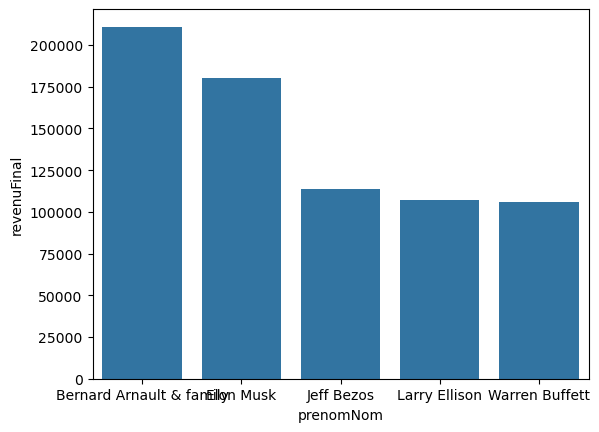

In [68]:
sns.barplot(df5, x= 'prenomNom',y= 'revenuFinal' ) # pour representer graphiquement le dataframe avec x et y pour preciser l'absice et l'ordonne avec sea
born

<Axes: xlabel='age', ylabel='counts'>

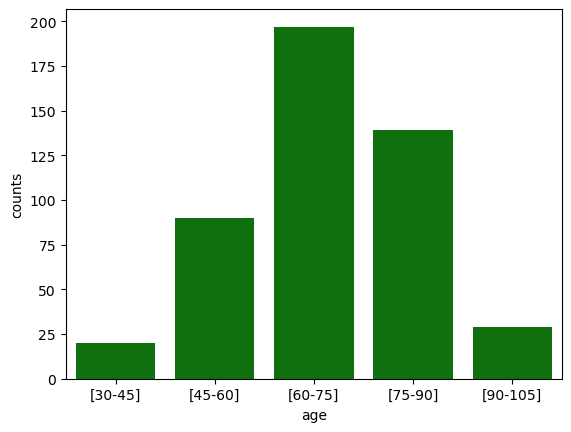

In [69]:
sns.barplot(df_intervals, color='green')